# Probabilistic hip-angle forecast ensemble

Does learning predictive variance add information beyond disagreement between point forecasts?

Read top-to-bottom: setup → equations → architecture → training → figures → LOTO → interpretation.
**Safe default:** saved-result exploration only; training is disabled.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'ml/sci_rob/vanilla/registry.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter within this repository.')
sys.path.insert(0, str(ROOT / 'notebooks/sci_rob/model_exploration'))
get_ipython().run_line_magic('matplotlib', 'inline')
from _exploration import *
import torch
from dataclasses import asdict
torch.set_num_threads(2)  # small architecture checks; training CLI runs separately
torch.manual_seed(0)
RUN_TRAINING = False
print('Repository:', ROOT)
print('Kernel:', sys.executable)

Repository: /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton
Kernel: /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/.venv/bin/python


In [2]:
KEY = 'prob_ensemble'
RUN = ROOT / RUNS[KEY]
inventory(RUN)

**Artifact directory:** `ml/sci_rob/prob_ensemble/runs/prob_forecast`

,artifact,available
0,report.json,True
1,final.pt,True
2,eval_test.json,True
3,figures,True


## Data and evaluation contract

- Input: **16 channels × 200 samples**, one second at 200 Hz; stored window stride 10 samples.
- Original ID tasks: level ground (LG), ramp ascent (RA), ramp descent (RD).
  Original pseudo-OOD tasks: stair ascent (SA), stair descent (SD), standing (ST), transitions (TR).
- Participants: 12 train / 4 validation / 4 test. Task availability differs by participant.
  Input scaling is fitted on training data, never refitted on test data.
- Scoring does **not** predict a task label. High $\Psi$ means more anomalous.

$$\widetilde\Psi_t=\operatorname{median}(\Psi_{t-9},\ldots,\Psi_t),\qquad
\tau=Q_{0.995}(\widetilde\Psi_{\mathrm{train,ID}}),\qquad
\widehat o_t=\mathbf1[\widetilde\Psi_t>\tau].$$

Filtering restarts for each trial; early windows use the available history. The ten-score
filter corresponds to the repository's nominal 0.5 s smoothing setting, **not** ten raw samples.

$$\mathrm{recall}=\frac{TP}{TP+FN},\quad
\mathrm{specificity}=\frac{TN}{TN+FP},\quad J=\mathrm{recall}+\mathrm{specificity}-1.$$

AUROC measures ranking across thresholds; it is **not the fraction of OOD detected**.
OOD is the positive class. Tables below show J on −1 to 1, although source JSON stores 100J.
Scores and thresholds are not calibrated probabilities of being unsafe.

## Model and mathematics

Each of seven TCNs emits a mean and log variance for each hip at t + 200 ms:
 $$p_m(y_d\mid x)=\mathcal N(\mu_{md}(x),\sigma_{md}^2(x)).$$
 The final linear head has four outputs (two means and two log variances); log variances
 are clamped to [−7,3]. After MSE warm-up, the masked training objective uses beta-NLL:
 $$\ell_\beta=\frac{\operatorname{stopgrad}(\sigma^2)^\beta}{2}
 \left[\log\sigma^2+\frac{(y-\mu)^2}{\sigma^2}\right],\qquad\beta=0.5.$$
 Loss is averaged across valid targets and branches; the constant Gaussian term is omitted
 from the training objective. **This beta weights likelihood gradients; it is not beta-VAE's KL weight.**

 For an equal-weight Gaussian mixture, averaged over the two output dimensions:
 $$U_{\rm alea}=\frac1D\sum_d\frac1M\sum_m\sigma_{md}^2,\quad
 U_{\rm epi}=\frac1D\sum_d\frac1M\sum_m(\mu_{md}-\bar\mu_d)^2,\quad
 U_{\rm total}=U_{\rm alea}+U_{\rm epi}.$$
 The fourth score is $U_{\rm epi}/(U_{\rm alea}+10^{-12})$. Each score has its own training
 threshold. The algebraic decomposition is exact for this mixture; interpreting its terms as
 pure physical noise versus novelty is not guaranteed. Changing the loss changes learned means.

 Calibration diagnostic: $z=(y-\mu)/\sigma$. A calibrated Gaussian requires more than a
 variance near one: inspect bias and interval coverage too. The reported `z_var` is a
 mask-weighted average of batch residual variances; the median window-averaged $z^2$ does not
 have a universal target of one and does not prove calibration.

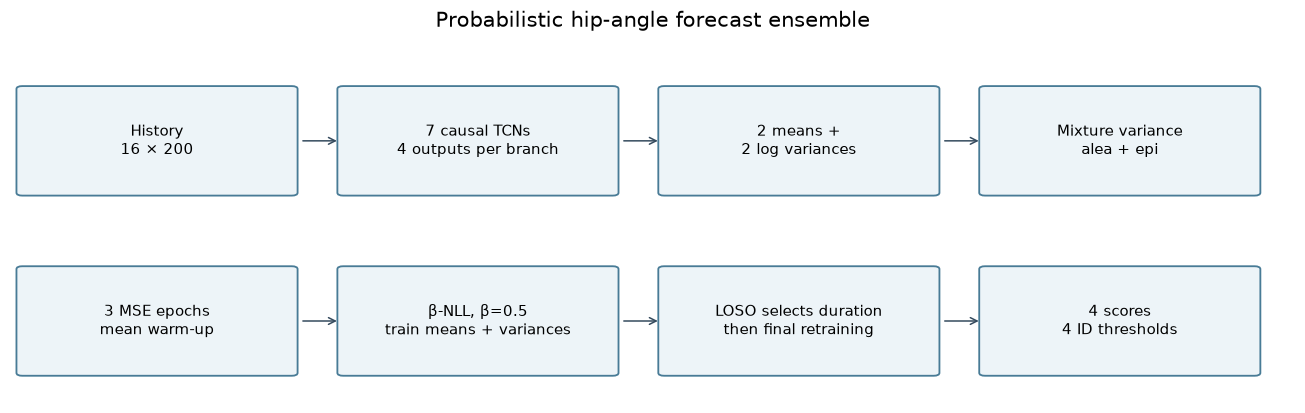

In [3]:
diagram([['History\n16 × 200', '7 causal TCNs\n4 outputs per branch', '2 means +\n2 log variances', 'Mixture variance\nalea + epi'], ['3 MSE epochs\nmean warm-up', 'β-NLL, β=0.5\ntrain means + variances', 'LOSO selects duration\nthen final retraining', '4 scores\n4 ID thresholds']], 'Probabilistic hip-angle forecast ensemble')

### Executable architecture check

This constructs **fresh random weights** and checks shapes only. The saved figures later come from trained runs; this dummy forward pass does not.

In [4]:
from prob_models import create_prob_ensemble
model = create_prob_ensemble(16, 2)
example = torch.zeros(2, 16, 200)
output = model_shapes(model, example)

ProbabilisticEnsemble: 321,958 parameters
Input: (2, 16, 200)   Outputs: [(2, 7, 2), (2, 7, 2)]
Layer table shows one representative branch; weights are not shared.


,module,class,direct parameters
0,network.0.conv,CausalConv1d,9630
1,network.0.norm,BatchNorm1d,60
2,network.0.relu,ReLU,0
3,network.1.conv,CausalConv1d,18030
4,network.1.norm,BatchNorm1d,60
5,network.1.relu,ReLU,0
6,network.2.conv,CausalConv1d,18030
7,network.2.norm,BatchNorm1d,60
8,network.2.relu,ReLU,0
9,fc,Linear,124


## Training

Twelve separate LOSO fold jobs, collection of selected epochs, then final retraining. Defaults: Adam LR 0.001, batch 1024, patience 10, three MSE warm-up epochs followed by beta-NLL with beta 0.5. The completed original run selected ten total epochs; the saved report below supplies the actual settings. Fold selection uses unweighted Gaussian NLL after warm-up.

In [5]:
from train import ProbConfig
display(pd.Series(asdict(ProbConfig()), name='current default').to_frame())

,current default
lr,0.001
batch_size,1024
max_epochs,60
patience,10
n_members,7
threshold_percentile,99.5
seed,0
beta,0.5
warmup_epochs,3
grad_clip,5.0


### Saved training configuration and learning curves

Current defaults can differ from a past run. Below we read the report; missing reports remain explicitly missing. Loss scales from different objectives are not directly comparable.

,saved value
lr,0.001
batch_size,1024
max_epochs,60
patience,10
n_members,7
threshold_percentile,99.5
seed,0
beta,0.5
warmup_epochs,3
grad_clip,5.0


,saved result
target,forecast_angle
horizon,40
n_epochs,10


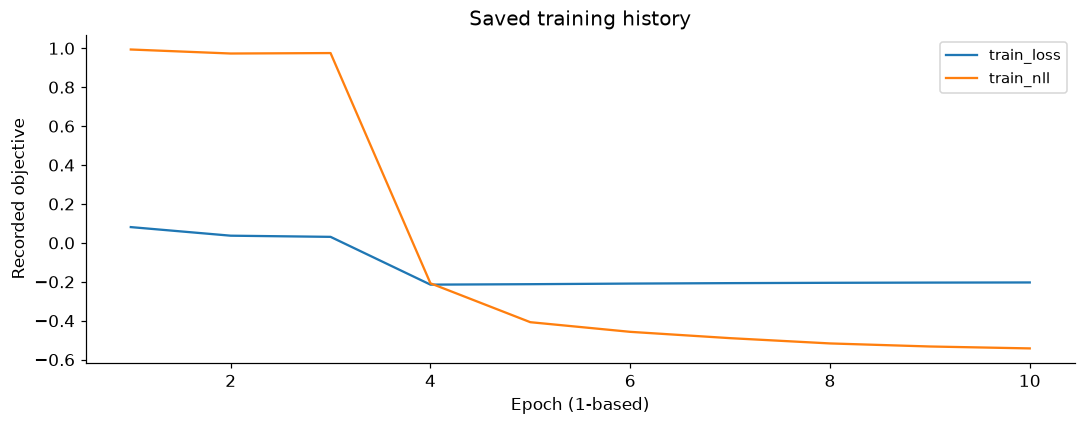

,epoch,phase,train_loss,train_nll,train_mse,mean_sigma,z_var,frac_clamped,seconds
5,5,nll,-0.209361,-0.457331,0.025775,0.157829,0.986085,0.0,99.2
6,6,nll,-0.207085,-0.489763,0.024335,0.152741,0.990678,0.0,98.8
7,7,nll,-0.205382,-0.516899,0.023161,0.148742,0.990309,0.0,98.6
8,8,nll,-0.204318,-0.532623,0.022496,0.146377,0.990049,0.0,98.4
9,9,nll,-0.203578,-0.542459,0.022120,0.144971,0.991692,0.0,98.7


**LOSO summary (epoch selection, not LOTO):**

{'n_epochs': 10,
 'n_folds': 12,
 'expected_folds': 12,
 'missing': [],
 'best_epochs': {'AB15': 4,
  'AB17': 13,
  'AB18': 16,
  'AB19': 13,
  'AB21': 3,
  'AB23': 14,
  'AB25': 3,
  'AB26': 13,
  'AB27': 10,
  'AB28': 6,
  'AB31': 11,
  'AB34': 16},
 'val_nll': {'AB15': 0.003863601966674199,
  'AB17': -0.2240318561015947,
  'AB18': 0.3737398582967463,
  'AB19': -0.04376889294855021,
  'AB21': -0.04718935097943536,
  'AB23': -0.16445271667323513,
  'AB25': 0.3192184872252073,
  'AB26': -0.43476274573741763,
  'AB27': -0.12220545915861156,
  'AB28': 0.9504389487705747,
  'AB31': -0.4043771904895512,
  'AB34': 0.07394400404236338},
 'val_z_var': {'AB15': 1.7996709966351467,
  'AB17': 1.760625993014444,
  'AB18': 2.5216928418026683,
  'AB19': 2.0069543735716078,
  'AB21': 1.666280623018481,
  'AB23': 1.3664826692445995,
  'AB25': 2.3214682596399516,
  'AB26': 1.1622130559038748,
  'AB27': 1.7725162393327334,
  'AB28': 4.1669675882075765,
  'AB31': 1.1586907214245108,
  'AB34': 1.90960084

In [6]:
config_and_history(RUN)

### Optional: run the real training pipeline

This can take hours. The commands use this kernel’s Python and write to a **new** directory. Set `RUN_TRAINING=True` in the setup cell only when ready. Existing runs are protected. After completion, set `RUN = NEW_RUN` and rerun the result cells.

In [7]:
NEW_RUN = ROOT / 'notebooks/sci_rob/model_exploration/runs' / KEY
commands = training_commands(KEY, NEW_RUN)
run_commands(commands, NEW_RUN, enabled=RUN_TRAINING)

/Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/.venv/bin/python /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/ml/sci_rob/prob_ensemble/train.py fold --index 0 --out /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/notebooks/sci_rob/model_exploration/runs/prob_ensemble
/Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/.venv/bin/python /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/ml/sci_rob/prob_ensemble/train.py fold --index 1 --out /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/notebooks/sci_rob/model_exploration/runs/prob_ensemble
/Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/.venv/bin/python /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/ml/sci_rob/prob_ensemble/train.py fold --index 2 --out /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/notebooks/sci_rob/model_ex

## Saved test results

These values come directly from `eval_test.json`. An optimized test-ROC threshold, where reported, is diagnostic—not a validated operating point.

In [8]:
results_table(RUN)

,AUROC,recall (%),specificity (%),J (−1 to 1),threshold
score,,,,,
epistemic,0.9144,28.1951,98.7975,0.2699,0.0142
aleatoric,0.7811,0.0955,99.9484,0.0004,0.0714
total,0.8759,1.2672,99.7305,0.0100,0.0813
ratio,0.8236,30.7946,96.4604,0.2725,0.4628


,saved calibration diagnostic
nll,7.289010
mse,0.052761
mean_sigma,0.144771
z_var,16.435966
frac_clamped,0.001245
z2_median,1.260093
z2_mean,16.567194
z2_p90,3.966663
z2_p99,10.566366
z2_share_top_0.1pct,0.584014


,mode,kind,windows,flagged_%,median
0,LG,ID,28668,2.2813,0.0039
1,RA,ID,18504,0.2216,0.0056
2,RD,ID,14784,0.3382,0.0041
3,SA,OOD,10273,18.0473,0.0097
4,SD,OOD,10155,30.1526,0.0108
5,TR,OOD,1994,48.1444,0.0124
6,ST,OOD,621,100.0000,0.0364


## Model behavior through figures

Images are embedded from the existing run, without rewriting it. Captions explain what each figure can and cannot establish.

**roc_compare.png** — Compare four candidate scores with point forecasting; no score is a universal winner across protocols.

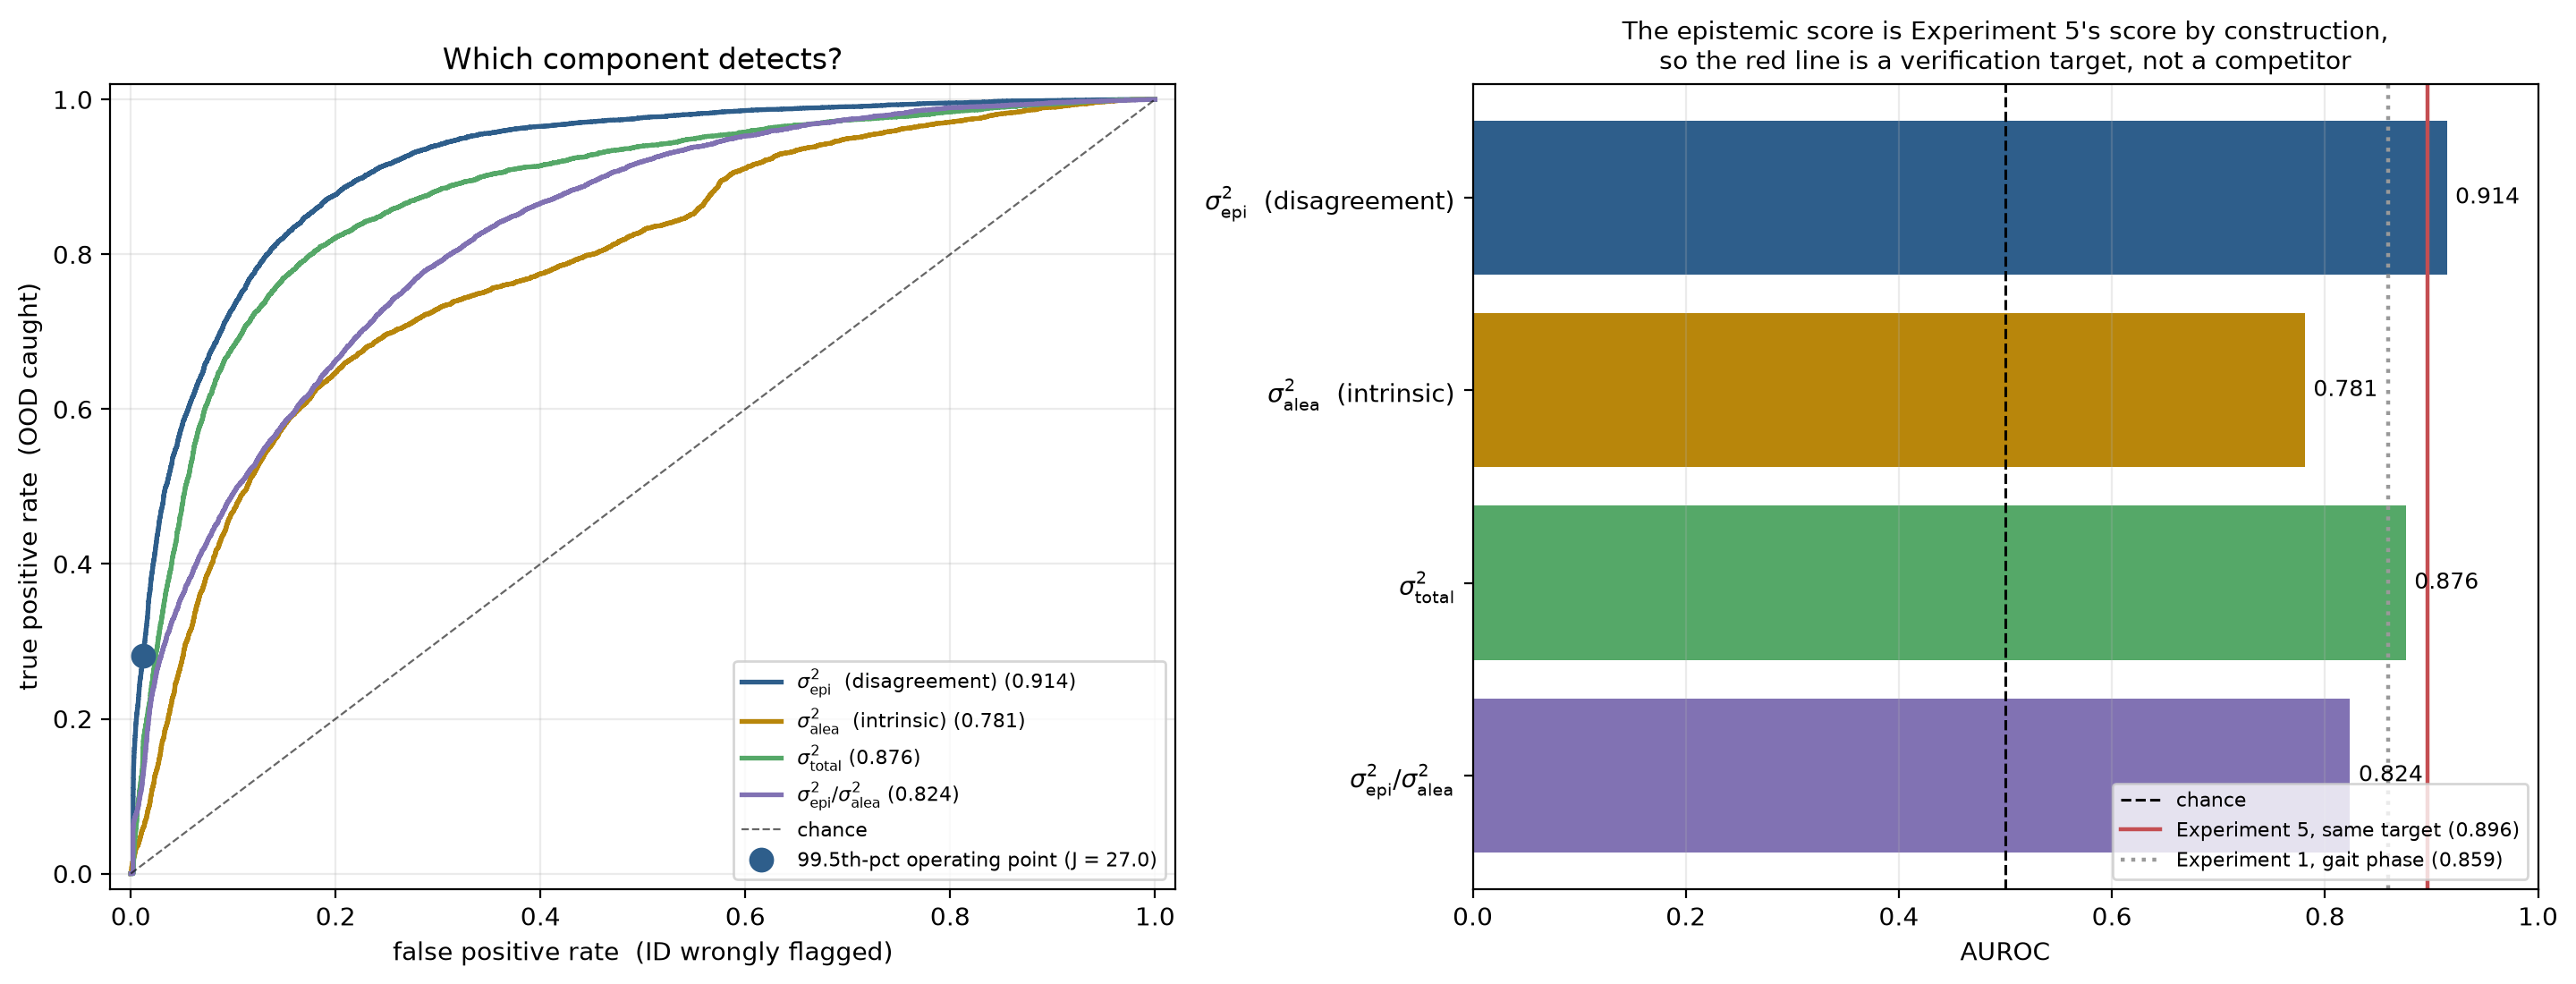

**alea_epi_plane.png** — Predicted variance and branch disagreement are distinct axes, not proof of a safety classification.

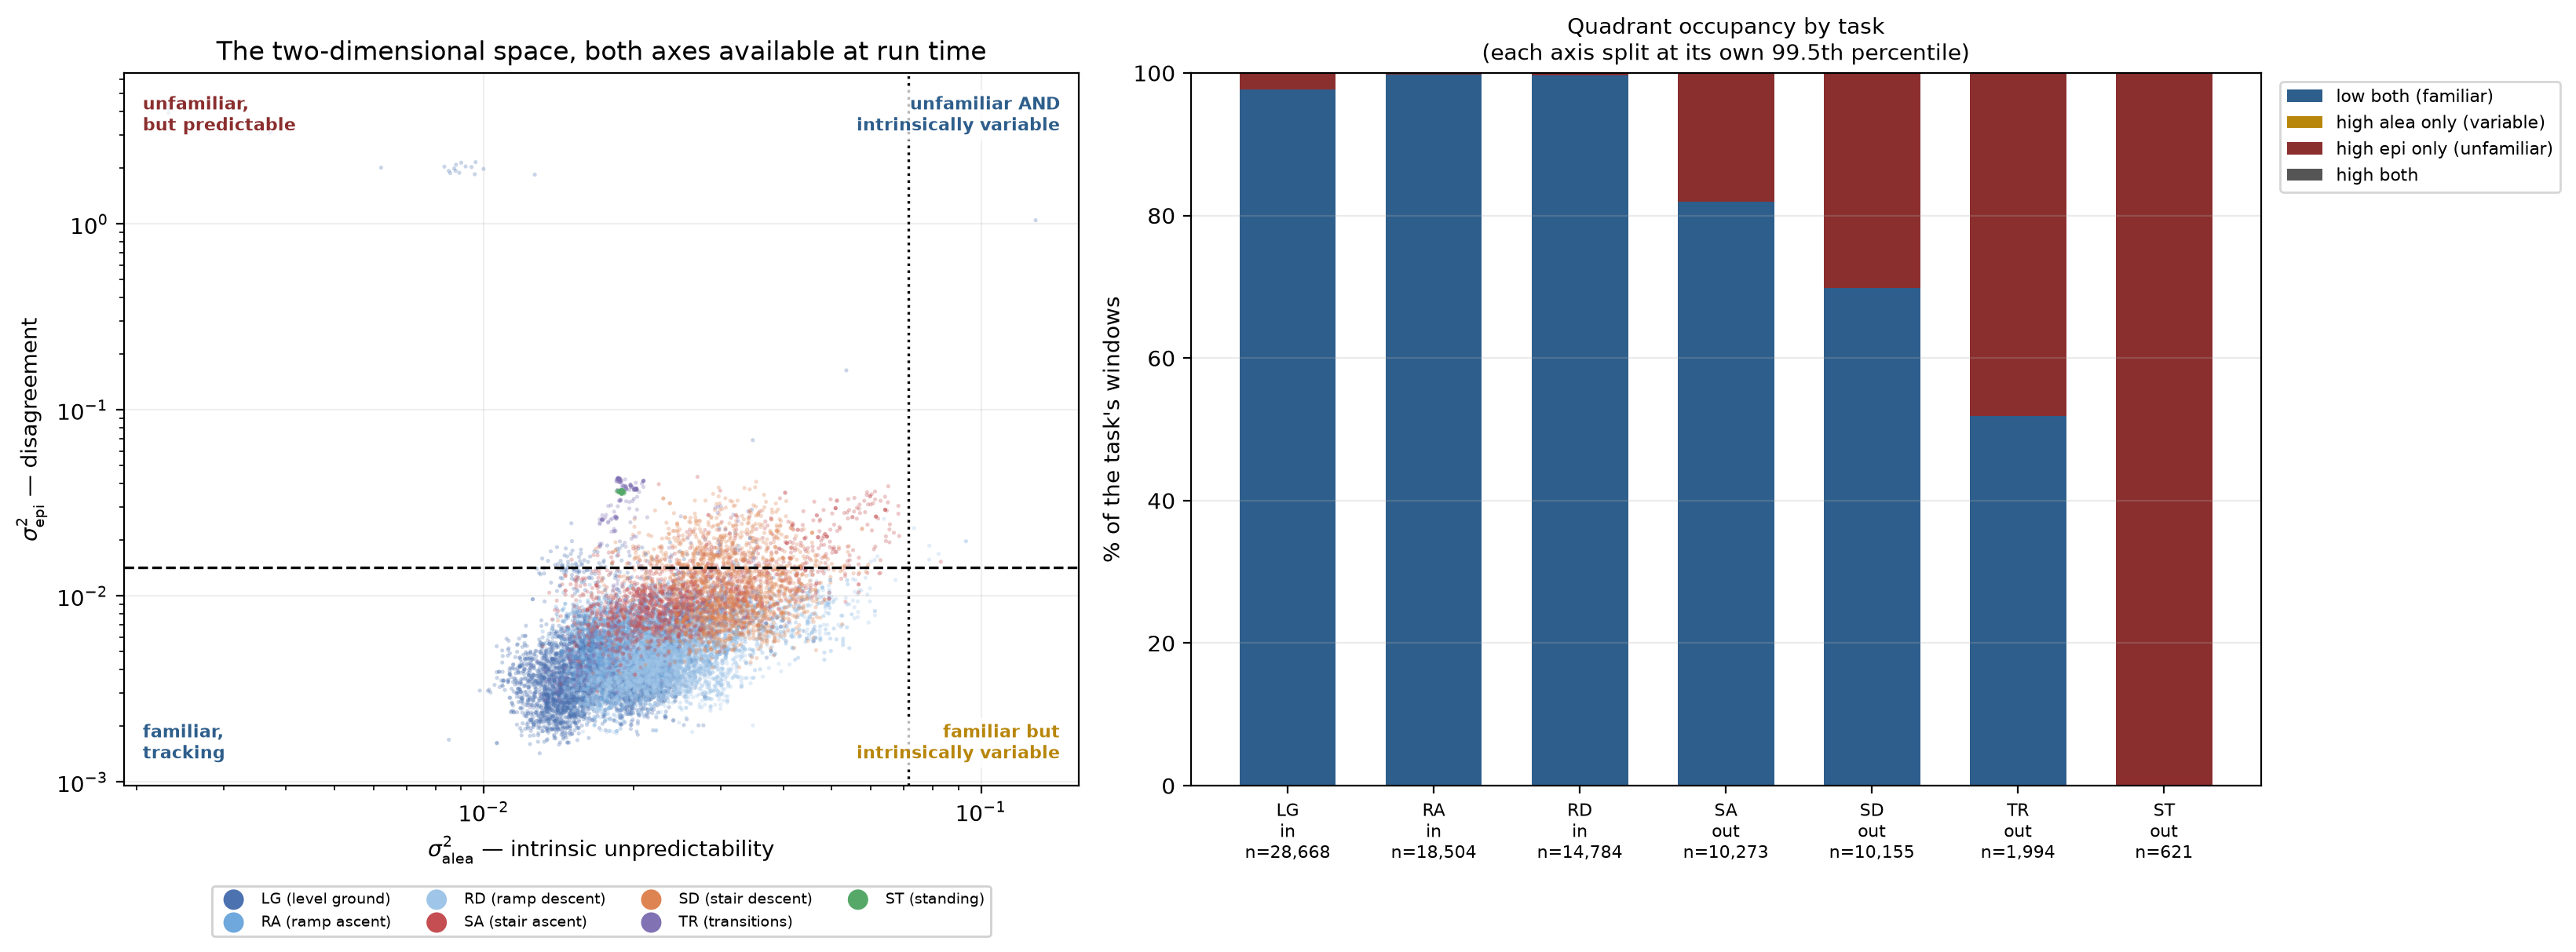

**sigma_by_task.png** — How predicted uncertainty and disagreement depend on task.

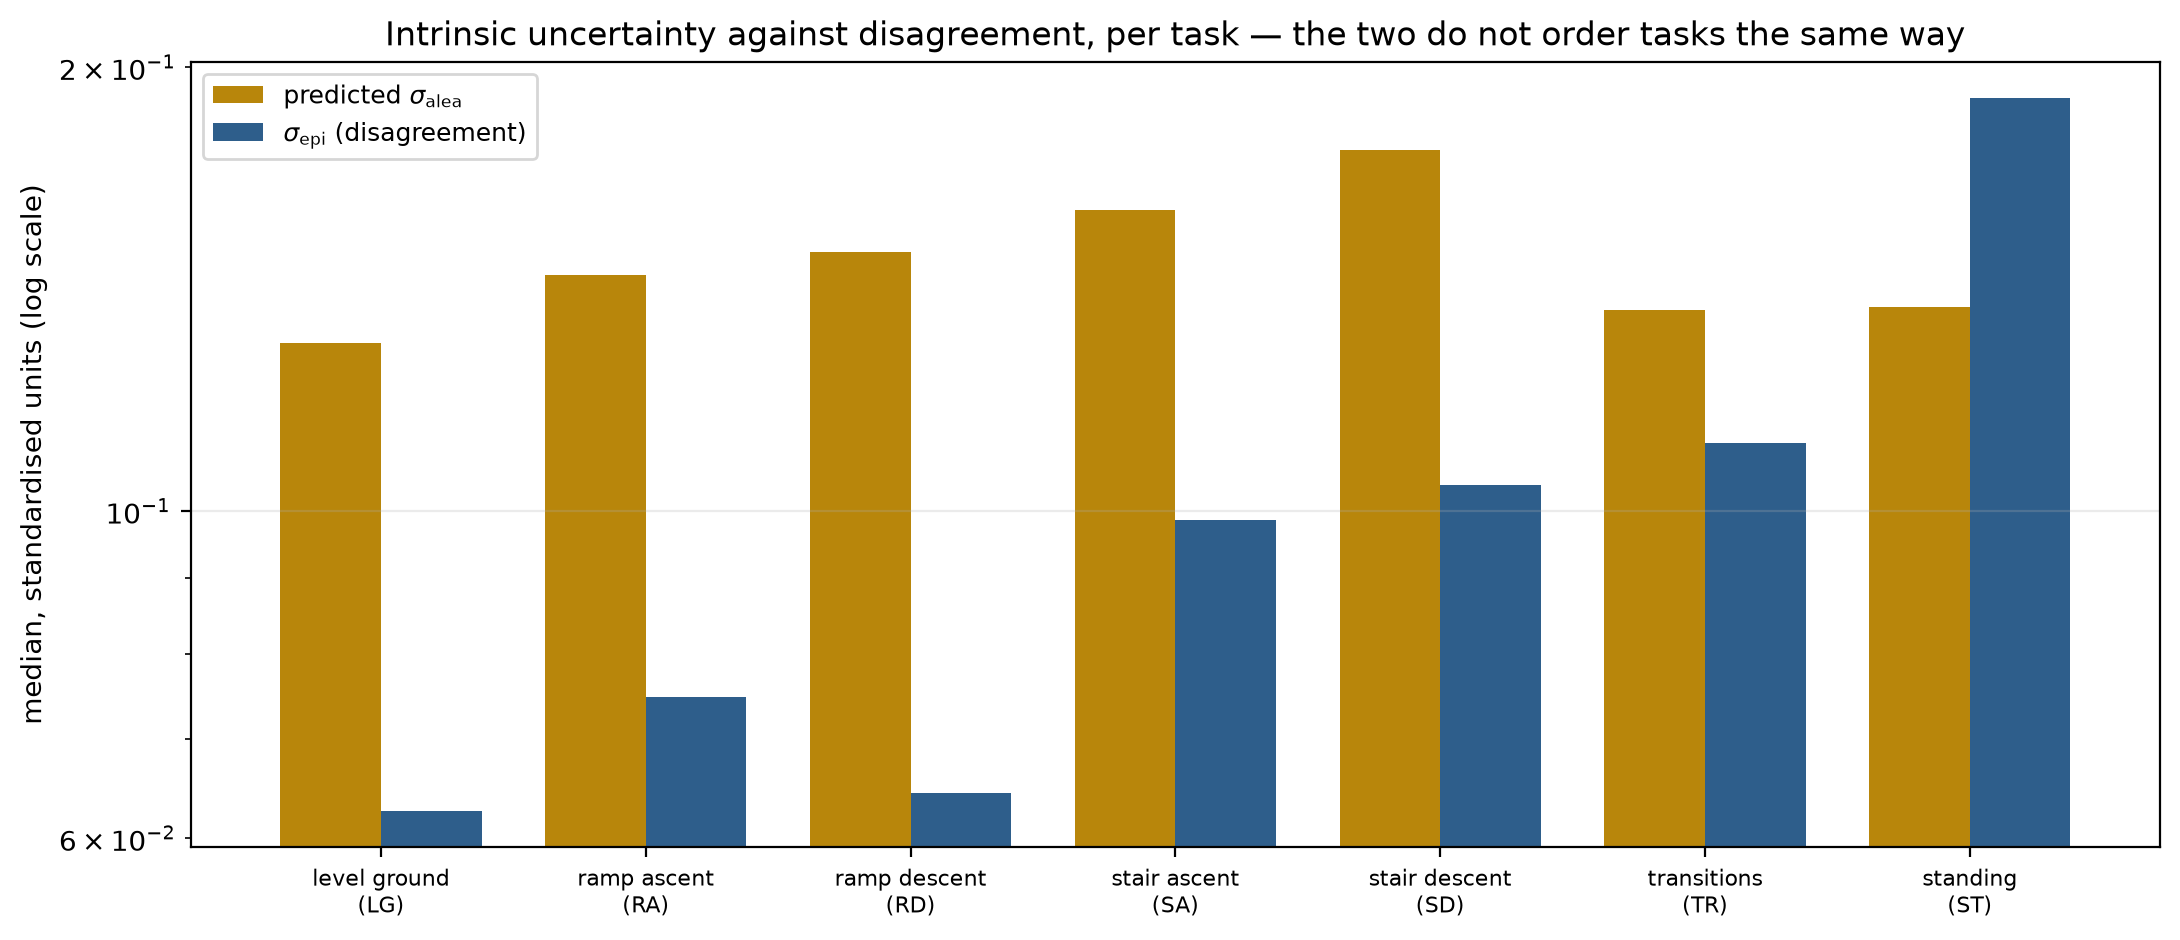

**scores_by_task.png** — Four score distributions; each uses its own scale and threshold.

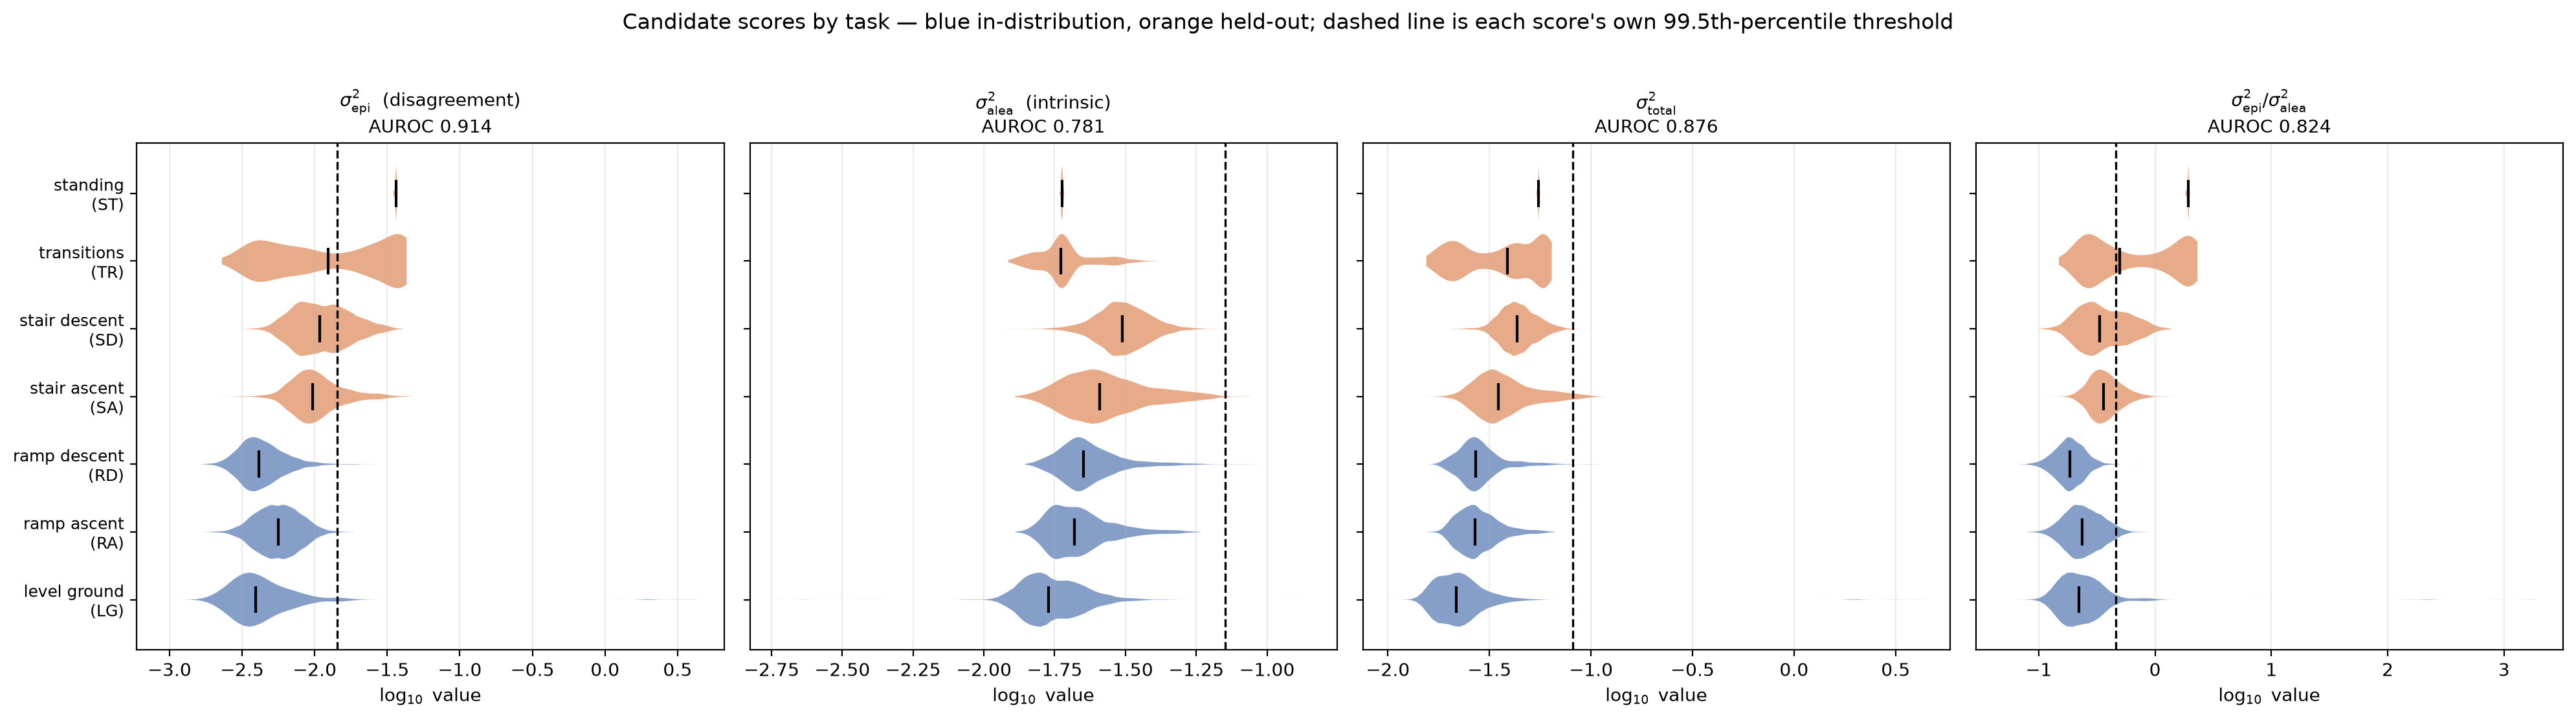

**calibration.png** — Saved training/LOSO diagnostics. A reference line at one applies to residual variance, not every z statistic.

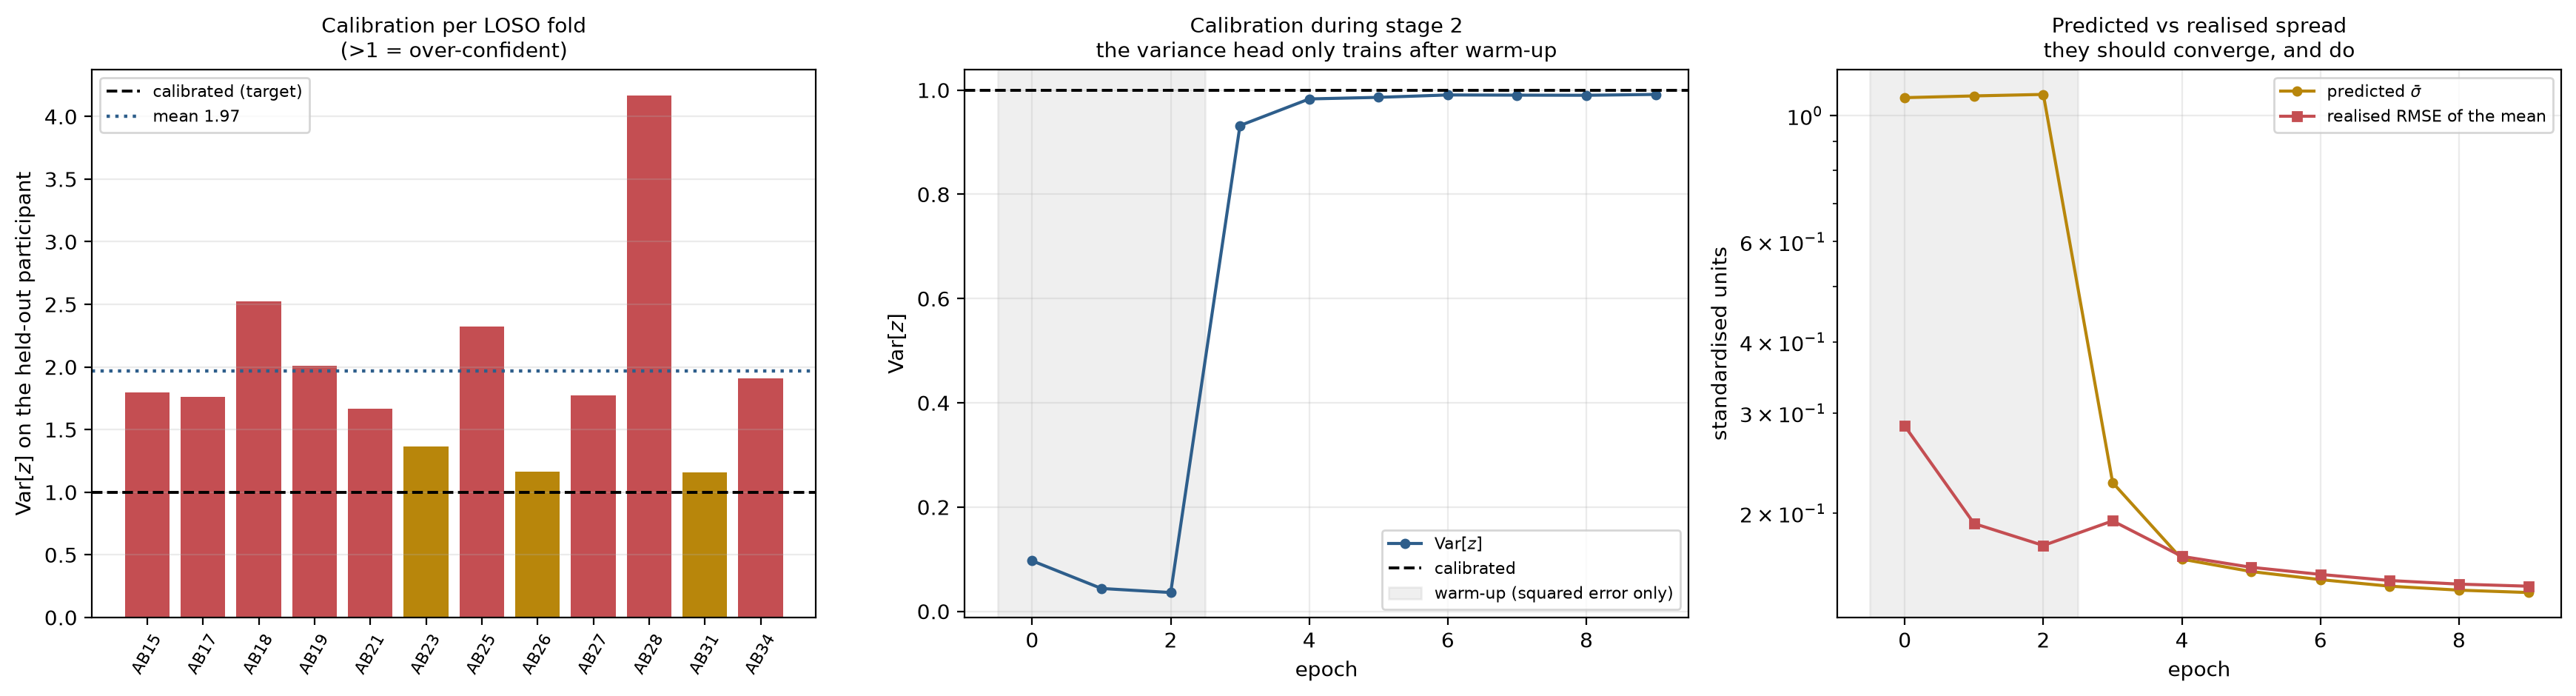

**detection_by_task.png** — Fixed-threshold behavior can worsen despite improved AUROC.

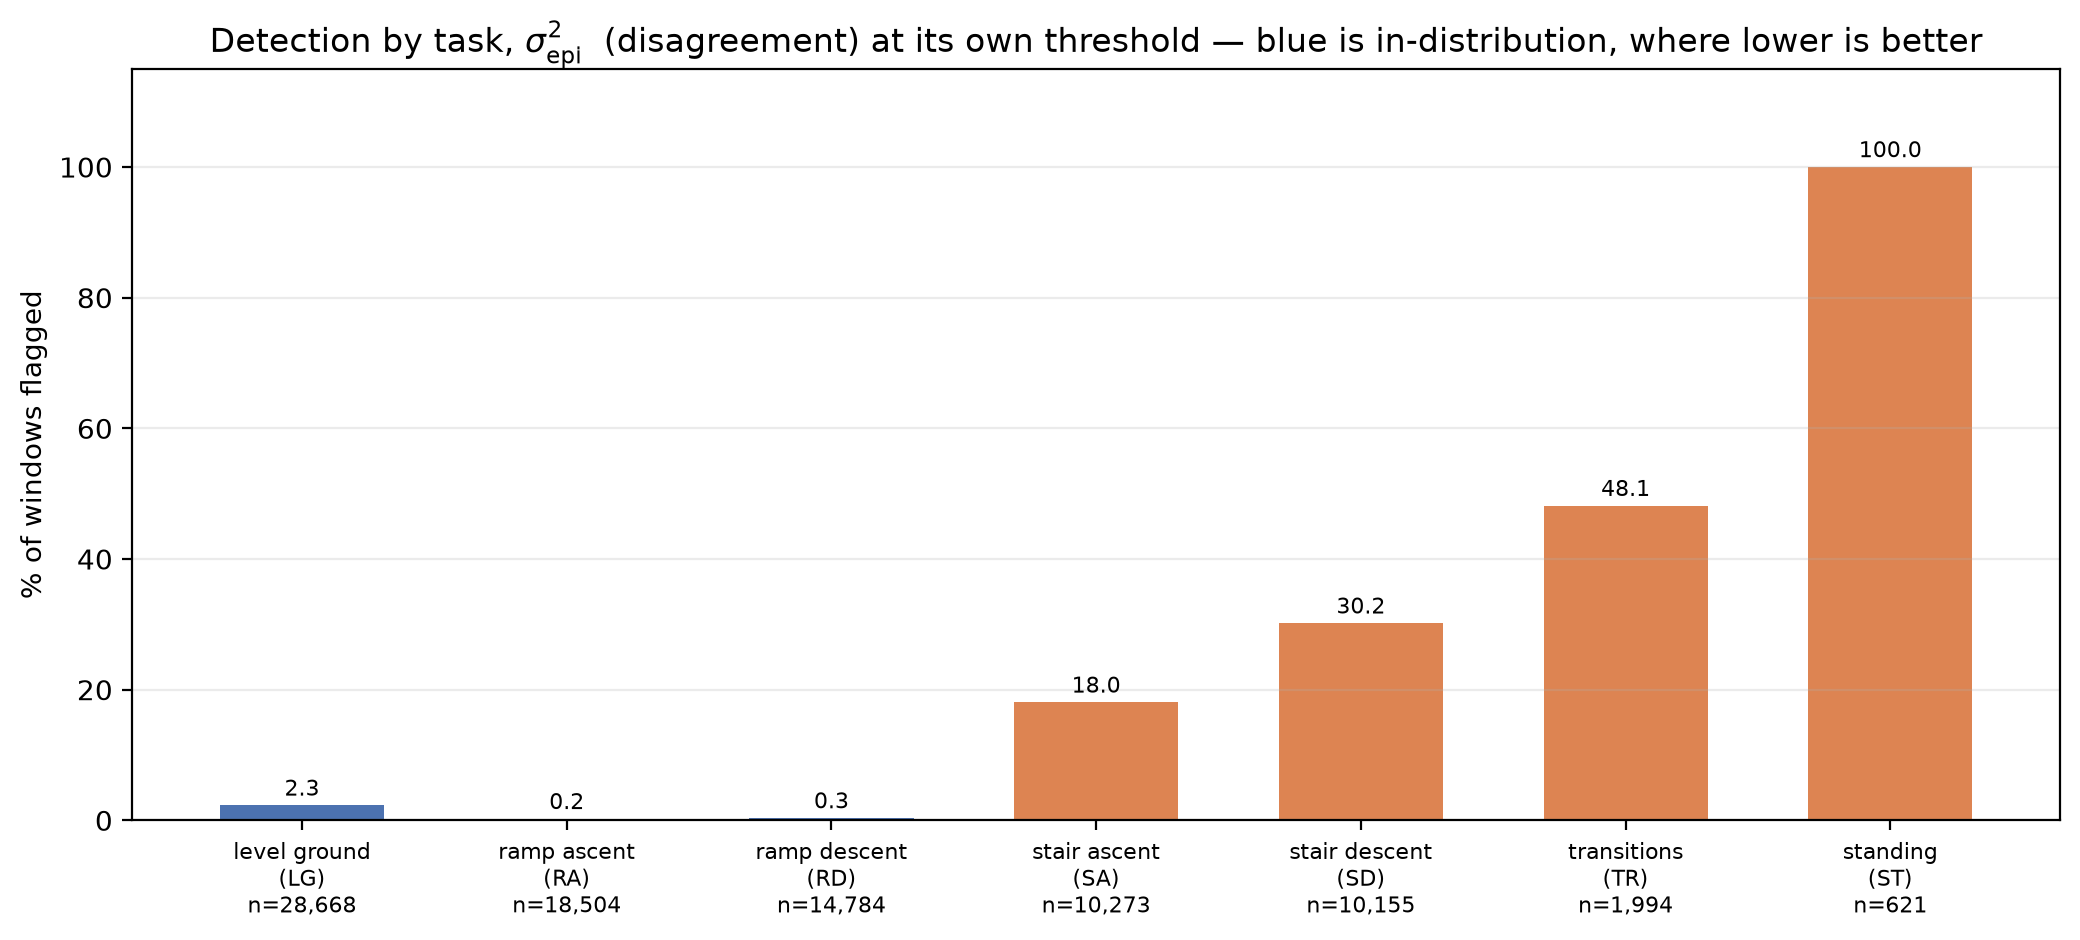

In [9]:
gallery(RUN, [('roc_compare.png', 'Compare four candidate scores with point forecasting; no score is a universal winner across protocols.'), ('alea_epi_plane.png', 'Predicted variance and branch disagreement are distinct axes, not proof of a safety classification.'), ('sigma_by_task.png', 'How predicted uncertainty and disagreement depend on task.'), ('scores_by_task.png', 'Four score distributions; each uses its own scale and threshold.'), ('calibration.png', 'Saved training/LOSO diagnostics. A reference line at one applies to residual variance, not every z statistic.'), ('detection_by_task.png', 'Fixed-threshold behavior can worsen despite improved AUROC.')])

## Leave-one-task-out (LOTO) stress test

SA: stair ascent; ST: standing; TR: transitions. Each run excludes the named task from **all training participants**, trains on the other six, and tests on held-out participants. This differs from LOSO epoch selection.

Standing test data come from one trial of one participant: 621 overlapping windows, or 600 for the gait-phase subset. Gait-phase LOTO uses fewer labelled windows overall. Raw window counts are not independent repetitions; cross-run changes do not isolate a causal training effect.

,held out,score,AUROC,recall (%),ID false alarms (%),J,OOD windows
0,SA,epistemic,0.8405,6.2202,1.8307,0.0439,10273
1,SA,aleatoric,0.7913,1.4017,0.0201,0.0138,10273
2,SA,total,0.8305,1.8982,0.2342,0.0166,10273
3,SA,ratio,0.6003,7.7582,4.1124,0.0365,10273
4,ST,epistemic,0.4802,0.0000,1.5632,-0.0156,621
5,ST,aleatoric,0.0287,0.0000,0.0664,-0.0007,621
6,ST,total,0.0845,0.0000,0.2335,-0.0023,621
7,ST,ratio,0.9242,0.0000,2.7436,-0.0274,621
8,TR,epistemic,0.5087,2.8084,1.1349,0.0167,1994
9,TR,aleatoric,0.2388,0.0000,0.1398,-0.0014,1994


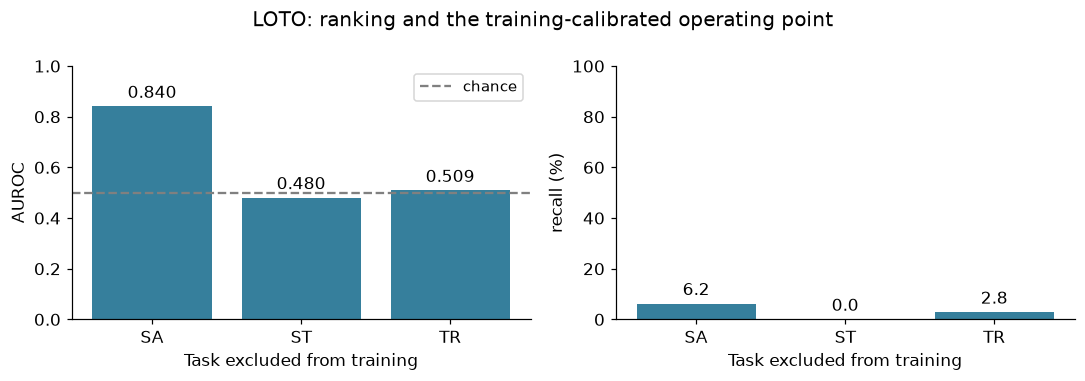

In [10]:
loto_results(KEY)

## LOTO score spread and threshold what-if

Each figure uses one separately trained holdout run: **only the named held-out task is
orange (OOD)**; the other six are blue (ID). The black dashed line is that run's saved
training threshold. Black bars span the middle 50% (IQR), with a tick at the median.
Density shapes use at most 1,500 quantile-spaced points per task; all medians, IQRs and
flag rates use **every saved test window**. Non-GAN scores use log10 axes when positive.
The plotted scores already include the original per-trial smoothing; they are not filtered again.

$$\operatorname{recall}(\tau)=\frac{\sum_{i:y_i=1}\mathbf{1}[\widetilde\Psi_i>\tau]}{N_{\rm OOD}},
\qquad \operatorname{FPR}(\tau)=\frac{\sum_{i:y_i=0}\mathbf{1}[\widetilde\Psi_i>\tau]}{N_{\rm ID}}.$$

**Try a threshold:** replace a `None` in `LOTO_THRESHOLDS` with a numeric score threshold
(in original units, **not log10**), then rerun this cell. A purple line and exact per-task
flag rates show the what-if; `None` uses the saved threshold. The right-hand staircase
and table show recall **and ID false alarms**, not AUROC. Changing the threshold does
not change AUROC, retrain anything, or overwrite saved results.

These are **exploratory test-set what-ifs**, not validated new operating points. Choose a
final threshold using validation data, not whichever test threshold looks best. Rates
are window-weighted; overlapping windows (especially the single standing trial) are
not independent repetitions. Missing runs remain explicitly unavailable.

### Held out: SA — stair ascent

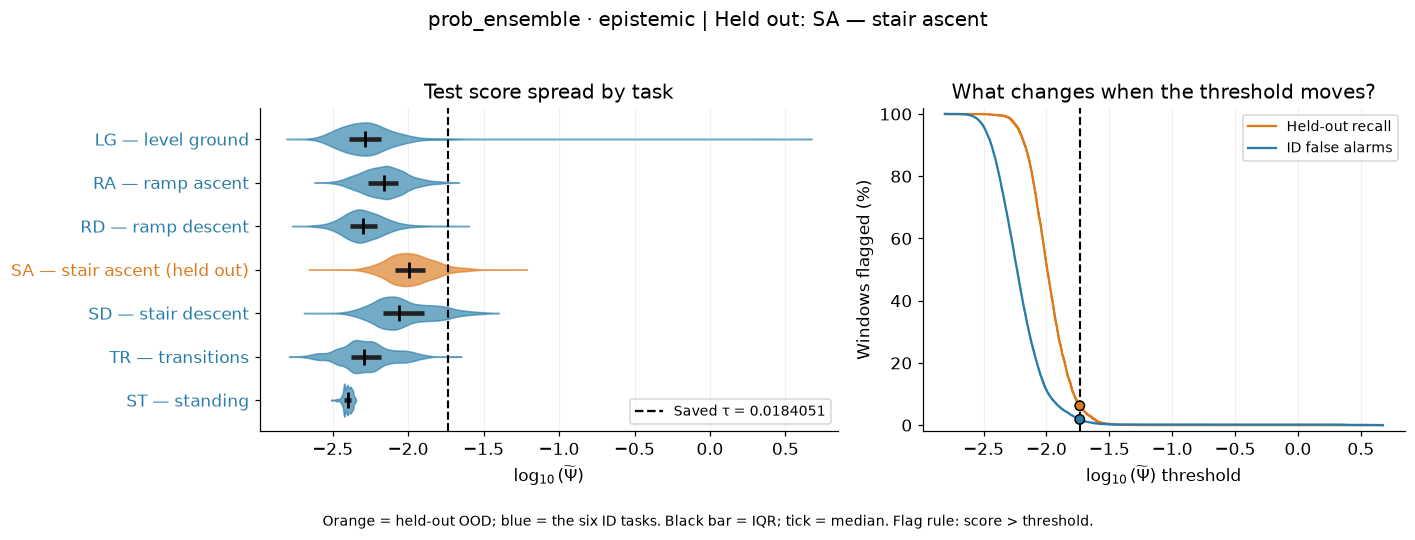

,point,threshold,OOD recall (%),ID false alarms (%)
0,,0.009202525,61.42,14.89
1,,0.013803788,20.86,4.72
2,,0.016564545,9.71,2.76
3,,0.017484798,7.76,2.33
4,,0.018221,6.45,1.92
5,saved,0.01840505,6.22,1.83
6,,0.018589101,6.01,1.75
7,,0.019325303,4.99,1.50
8,,0.020245555,4.20,1.20
9,,0.023006313,2.38,0.76


**Per-task flags at τ = 0.01840505** (recall on the held-out task; false alarms on each ID task).

,task,role,windows,flagged (%)
0,LG,ID,28668,1.39
1,RA,ID,18504,0.27
2,RD,ID,14784,0.19
3,SA,held-out OOD,10273,6.22
4,SD,ID,10155,8.67
5,TR,ID,1994,0.55
6,ST,ID,621,0.00


### Held out: ST — standing

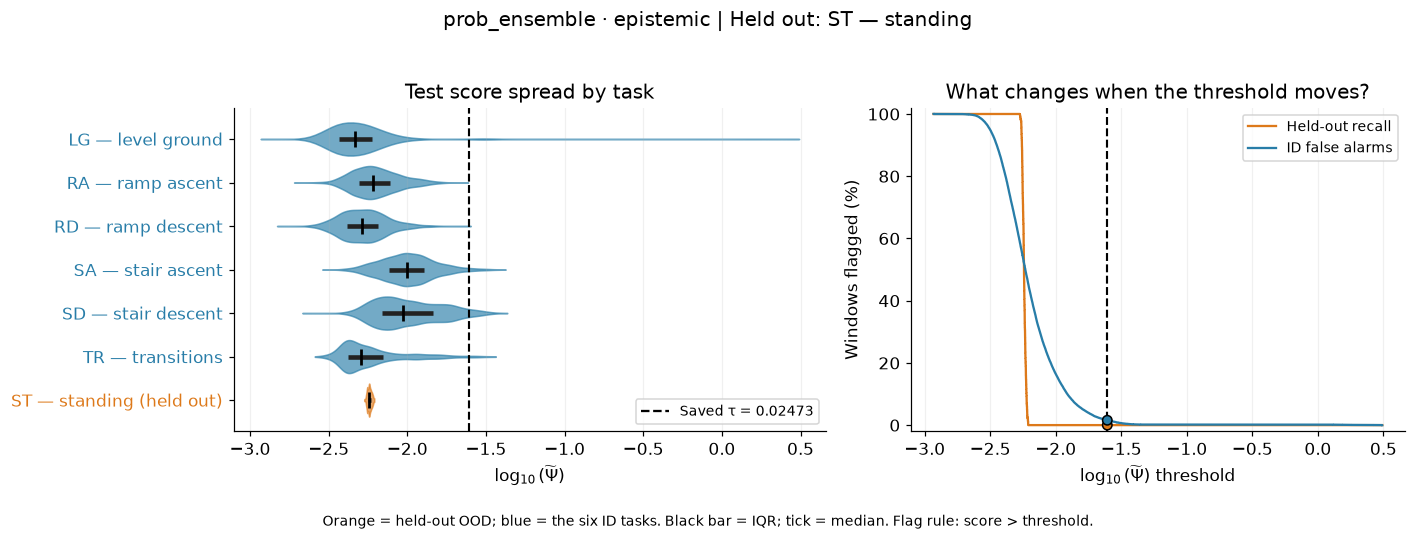

,point,threshold,OOD recall (%),ID false alarms (%)
0,,0.012365018,0.00,9.75
1,,0.018547527,0.00,3.52
2,,0.022257032,0.00,2.10
3,,0.023493534,0.00,1.85
4,,0.024482736,0.00,1.62
5,saved,0.024730036,0.00,1.56
6,,0.024977336,0.00,1.53
7,,0.025966538,0.00,1.36
8,,0.02720304,0.00,1.17
9,,0.030912545,0.00,0.70


**Per-task flags at τ = 0.024730036** (recall on the held-out task; false alarms on each ID task).

,task,role,windows,flagged (%)
0,LG,ID,28668,2.14
1,RA,ID,18504,0.00
2,RD,ID,14784,0.01
3,SA,ID,10273,2.12
4,SD,ID,10155,4.40
5,TR,ID,1994,1.91
6,ST,held-out OOD,621,0.00


### Held out: TR — transitions

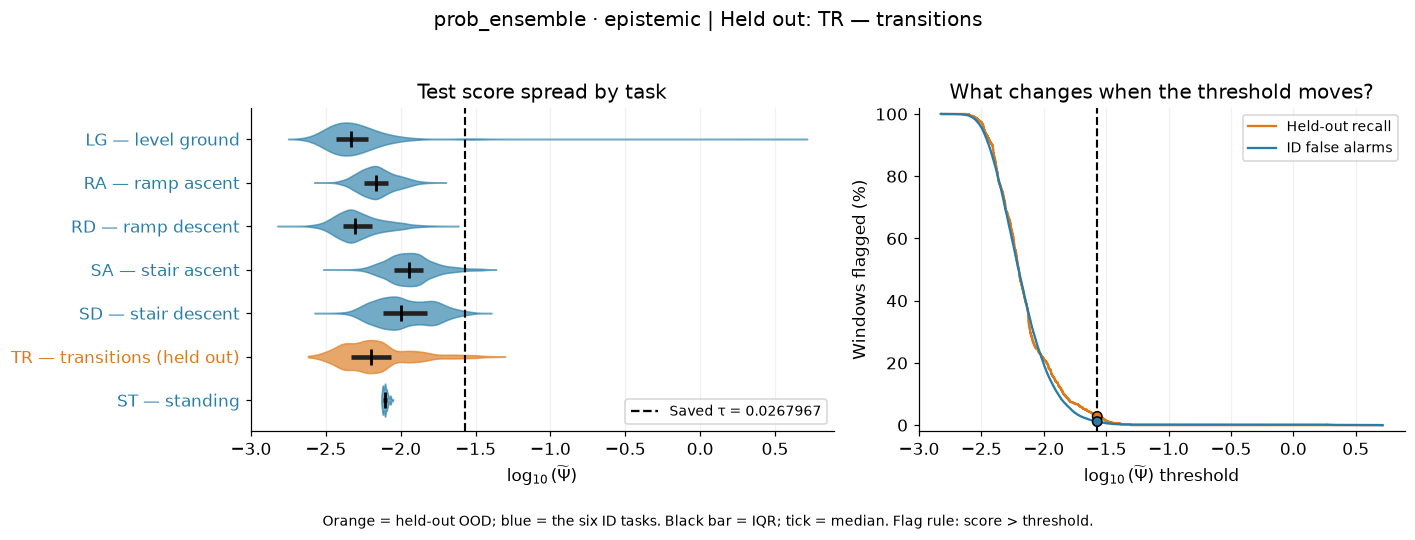

,point,threshold,OOD recall (%),ID false alarms (%)
0,,0.013398328,12.34,9.20
1,,0.020097492,5.72,2.71
2,,0.02411699,3.96,1.58
3,,0.025456823,3.21,1.34
4,,0.026528689,2.86,1.17
5,saved,0.026796656,2.81,1.13
6,,0.027064622,2.66,1.09
7,,0.028136489,2.51,0.95
8,,0.029476321,2.16,0.82
9,,0.03349582,1.00,0.49


**Per-task flags at τ = 0.026796656** (recall on the held-out task; false alarms on each ID task).

,task,role,windows,flagged (%)
0,LG,ID,28668,2.01
1,RA,ID,18504,0.00
2,RD,ID,14784,0.00
3,SA,ID,10273,2.26
4,SD,ID,10155,1.33
5,TR,held-out OOD,1994,2.81
6,ST,ID,621,0.00


In [11]:
from _loto_exploration import loto_score_explorer, threshold_rates
LOTO_THRESHOLDS = {'SA': None, 'ST': None, 'TR': None}
# Other saved scores: 'aleatoric', 'total', 'ratio'.
LOTO_SCORE = 'epistemic'
loto_bundles = loto_score_explorer(KEY, score=LOTO_SCORE, thresholds=LOTO_THRESHOLDS)
# Exact custom query, e.g.: threshold_rates(loto_bundles['ST'], [0.59, 0.60])

## Takeaway and next checks

The original run improves epistemic AUROC but reduces fixed-threshold recall versus point forecasting. LOTO shows that the ratio can help on some tasks; its poorer original result does not justify rejecting it everywhere. Predicted variance is not yet calibrated assurance on a new wearer.

Keep score/threshold selection on validation data. Report both ranking and recall at a declared false-alarm budget, repeat seeds, and quantify participant/trial-level variation before making robustness claims.

In [12]:
source_links(['ml/sci_rob/prob_ensemble/prob_models.py', 'ml/sci_rob/prob_ensemble/losses.py', 'ml/sci_rob/prob_ensemble/train.py', 'ml/sci_rob/prob_ensemble/evaluate.py'])

Implementation sources: [prob_models.py](../../../ml/sci_rob/prob_ensemble/prob_models.py), [losses.py](../../../ml/sci_rob/prob_ensemble/losses.py), [train.py](../../../ml/sci_rob/prob_ensemble/train.py), [evaluate.py](../../../ml/sci_rob/prob_ensemble/evaluate.py)